In [8]:
import pandas as pd

In [9]:
data_raw = pd.read_excel('data_file_2025_45_points.xlsx')

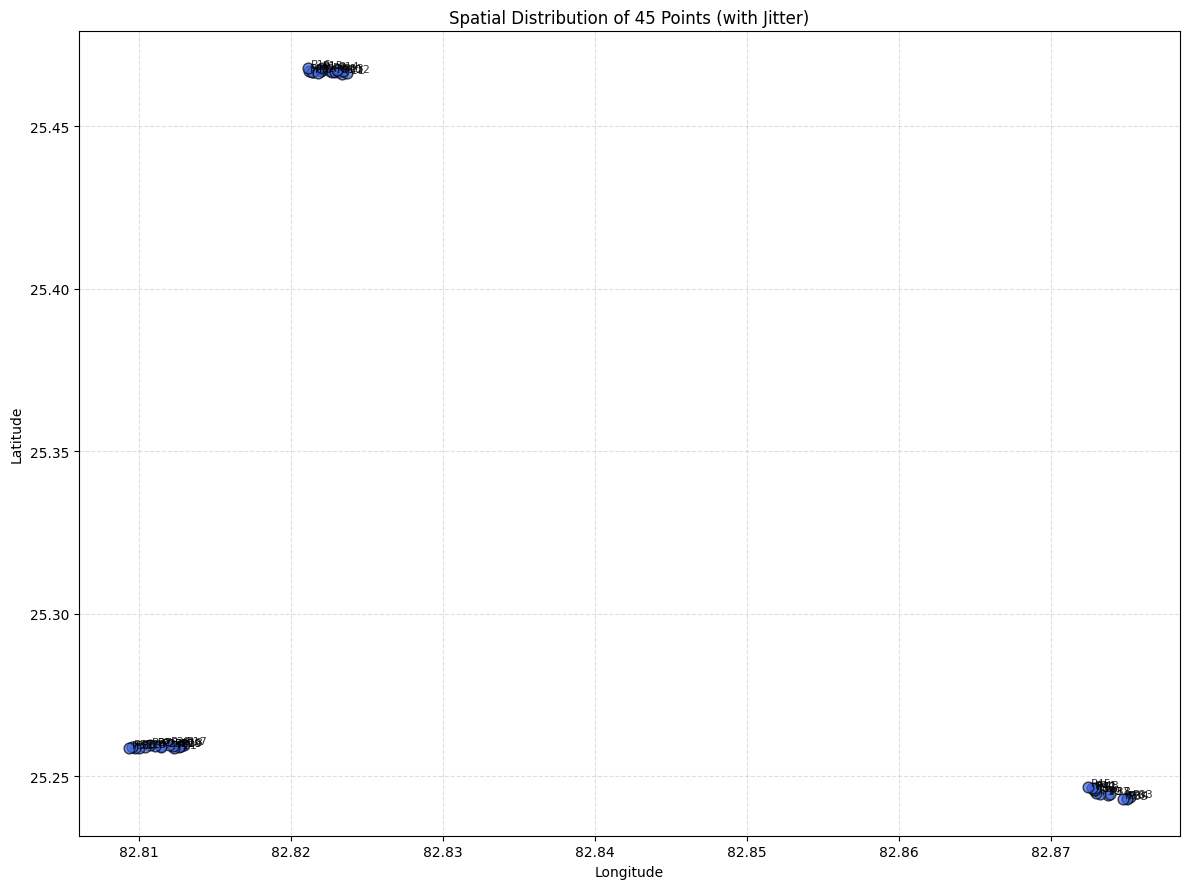

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Keep one coordinate per point (same points repeated across dates)
points = data_raw[['Point_ID', 'LAT', 'LON']].drop_duplicates(subset='Point_ID')

plt.figure(figsize=(12, 9))  # Larger figure for clarity


# Add jitter to points if many overlap (small random noise)
jitter_strength = 0.0001
lon_jittered = points['LON'] + np.random.uniform(-jitter_strength, jitter_strength, size=len(points))
lat_jittered = points['LAT'] + np.random.uniform(-jitter_strength, jitter_strength, size=len(points))

plt.scatter(lon_jittered, lat_jittered, s=60, c='royalblue', edgecolor='black', alpha=0.7, zorder=2)

# Optional: label each point
for i, row in points.iterrows():
    plt.text(row['LON'] + 0.00015, row['LAT'] + 0.00015, row['Point_ID'], fontsize=8, alpha=0.8, zorder=3)

plt.title('Spatial Distribution of 45 Points (with Jitter)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.4, zorder=1)
plt.tight_layout()
plt.show()

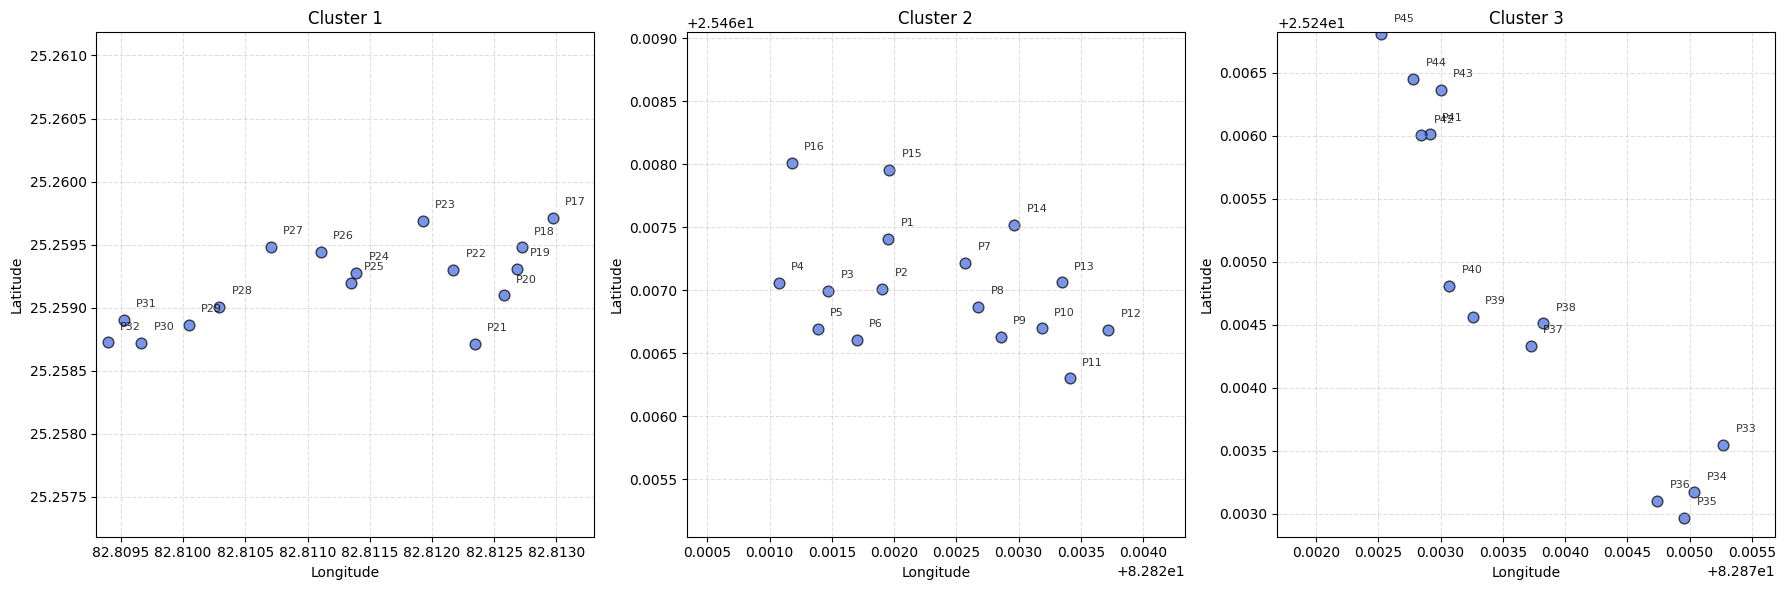

In [7]:
# --- Zoom in on the 3 main clusters ---
from sklearn.cluster import KMeans

# Prepare coordinates for clustering
coords = points[['LAT', 'LON']].values
kmeans = KMeans(n_clusters=3, random_state=42)
labels = kmeans.fit_predict(coords)
centers = kmeans.cluster_centers_

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for i in range(3):
    ax = axes[i]
    cluster_points = points[labels == i]
    ax.scatter(cluster_points['LON'], cluster_points['LAT'], s=60, c='royalblue', edgecolor='black', alpha=0.7)
    for _, row in cluster_points.iterrows():
        ax.text(row['LON'] + 0.0001, row['LAT'] + 0.0001, row['Point_ID'], fontsize=8, alpha=0.8)
    # Zoom in on cluster center
    center_lat, center_lon = centers[i]
    ax.set_xlim(center_lon - 0.002, center_lon + 0.002)
    ax.set_ylim(center_lat - 0.002, center_lat + 0.002)
    ax.set_title(f'Cluster {i+1}')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [13]:
# --- ML model for Soil Moisture prediction using VV, VH, and Point_ID ---
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder

# Encode Point_ID as categorical
le = LabelEncoder()
data_raw['Point_ID_enc'] = le.fit_transform(data_raw['Point_ID'])

# Select features and target
days = 6  # Use 6 days of data (if you want to filter, otherwise use all)
unique_dates = sorted(data_raw['Date'].unique())[:days]
data_ml = data_raw[data_raw['Date'].isin(unique_dates)]

X = data_ml[['VV_dB', 'VH_dB', 'Point_ID_enc']]
y = data_ml['SM']

# Split data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train model
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predict and evaluate
y_pred = model.predict(X_test)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

# Example: Predict for new data
# new_data = pd.DataFrame({'VV_dB': [-8.5], 'VH_dB': [-15.1], 'Point_ID_enc': [le.transform(['P1'])[0]]})
# print(model.predict(new_data))

RMSE: 0.1046
R2 Score: 0.0865
